<a href="https://colab.research.google.com/github/csiyu0962-collab/DataScience-GenAI-Submissions/blob/main/5_02_Modelling_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 5.02 Modelling Hackathon
We'll get a chance in this seminar to practice for the in-class test, and also to put what we have learned into practice.

To speed things up, I have done the data/feature engineering for you, you will just need to build it into a data science model. As before, you can use the code from [GitHub](https://github.com/MJMortensonWarwick/IB2AD0_Data_Science_GenerativeAI), from the internet, and/or use the Gemini AI tools.

This is an artificial dataset, and we will be predicting if students achieve a passing grade, which we will call anything above a "D".

We'll start by importing the data:

In [1]:
from google.colab import files
upload = files.upload()

Saving students_two.xlsx to students_two.xlsx


Now we will get the data into Pandas and inspect it:

In [3]:
import pandas as pd
df = pd.read_excel("students_two.xlsx")

df.head()

,Id,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,5001,21,Other,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,5002,20,Other,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,5003,21,State,0.5,No,No,Private,2,Never,No,No,No,Yes,AA
3,5004,18,Private,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,5005,22,Private,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


#1. data preprocessing


Let's check for missing values:

In [4]:
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,1
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


Only one missing value. Let's just drop it out of laziness:

In [ ]:
df.dropna(inplace=True)
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,0
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


We have an ID column we know won't be predictive ... so let's drop it:

In [ ]:
df = df.drop(["Id"], axis=1)
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,20,Other,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,21,State,0.5,No,No,Private,2,Never,No,No,No,Yes,AA
3,18,Private,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,22,Private,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Next we will convert some of the text features to numbers:

In [ ]:
# High school
print(df['High_School_Type'].unique())

['Other' 'State' 'Private']


We can't easily convert these to a number range. Instead we should use one-hot encoding:

In [5]:
df = pd.get_dummies(df, columns=['High_School_Type'], drop_first=True, dtype=int)
df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,5002,20,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,5003,21,0.5,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,5004,18,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,5005,22,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


We have converted this to two columns (on the far right) - "High_School_Type_Private" and "High_School_Type_State". We do not need the "Other" type as if the student is "Other" then both "Private" and "State" will be 0 (a unique combination). This is controlled by the command _drop\_first=True_. We also specify the data type (_dtype_) as __int__ so we return 0s and 1s rather than True and False.

Next we can look at Scholarship. It needs to be converted from a text representation of a percentage to a number:

In [6]:
# 此时 'Scholarship' 列在读取 Excel 时已被自动识别为浮点数类型（如 0.5），无需进行字符串转换。
df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,5002,20,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,5003,21,0.5,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,5004,18,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,5005,22,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


"Additional_Work" is next:

In [7]:
# Additional work
print(df['Additional_Work'].unique())

['Yes' 'No']


Two values, so we can convert to 0 and 1:

In [8]:
df['Additional_Work'] = df['Additional_Work'].map({'Yes': 1, 'No': 0})
df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,5002,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,5003,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,5004,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,5005,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Let's speed up now:

In [9]:
categorical_cols = ['Sports_activity', 'Transportation', 'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work', 'Grade']

for col in categorical_cols:
    print(f"Unique values for '{col}': {df[col].unique()}")

Unique values for 'Sports_activity': ['No' 'Yes']
Unique values for 'Transportation': ['Private' 'Bus']
Unique values for 'Attendance': ['Always' 'Never' 'Sometimes' 3]
Unique values for 'Reading': ['Yes' 'No']
Unique values for 'Notes': ['Yes' 'No' 6]
Unique values for 'Listening_in_Class': ['No' 'Yes' 6]
Unique values for 'Project_work': ['No' 'Yes']
Unique values for 'Grade': ['AA' 'BA' 'CC' 'Fail' 'BB' 'CB' 'DD' 'DC']


The values of '6' in 'Notes' and 'Listening_in_Class' make no sense, and neither do '3' for 'Attendance'. We'll be lazy and drop these rows (really we should check with an SME):

In [10]:
df = df[(df['Notes'] != '6') & (df['Listening_in_Class'] != '6') & (df['Attendance'] != '3')]
df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,5002,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,5003,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,5004,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,5005,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Now we can convert all those "Yes" / "No" columns to 0 and 1.

In [11]:
binary_cols = ['Sports_activity', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,1,0,Private,0,Always,1,1.0,0.0,0,AA,0,0
1,5002,20,0.5,1,0,Private,0,Always,1,0.0,1.0,1,AA,0,0
2,5003,21,0.5,0,0,Private,2,Never,0,0.0,0.0,1,AA,0,1
3,5004,18,0.5,1,0,Bus,2,Always,0,1.0,0.0,0,AA,1,0
4,5005,22,0.5,0,0,Bus,12,Always,1,0.0,1.0,1,AA,1,0


We can also do this with "Transportation":

In [12]:
df['Transportation'] = df['Transportation'].map({'Private': 1, 'Bus': 0})
df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,1,0,1,0,Always,1,1.0,0.0,0,AA,0,0
1,5002,20,0.5,1,0,1,0,Always,1,0.0,1.0,1,AA,0,0
2,5003,21,0.5,0,0,1,2,Never,0,0.0,0.0,1,AA,0,1
3,5004,18,0.5,1,0,0,2,Always,0,1.0,0.0,0,AA,1,0
4,5005,22,0.5,0,0,0,12,Always,1,0.0,1.0,1,AA,1,0


For Attendance an ordinal range makes sense:

In [13]:
df['Attendance'] = df['Attendance'].map({'Never': 0, 'Sometimes': 1, 'Always': 2})
df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,1,0,1,0,2.0,1,1.0,0.0,0,AA,0,0
1,5002,20,0.5,1,0,1,0,2.0,1,0.0,1.0,1,AA,0,0
2,5003,21,0.5,0,0,1,2,0.0,0,0.0,0.0,1,AA,0,1
3,5004,18,0.5,1,0,0,2,2.0,0,1.0,0.0,0,AA,1,0
4,5005,22,0.5,0,0,0,12,2.0,1,0.0,1.0,1,AA,1,0


This just leaves the target - 'Grade'. To make the problem binary we'll convert 'Fail' and any grade that includes a 'D' as 0 (for fail) and the rest as 1 (pass):

In [14]:
df['Grade'] = df['Grade'].apply(lambda x: 0 if x == 'Fail' or 'D' in x else 1)
df.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,1,0,1,0,2.0,1,1.0,0.0,0,1,0,0
1,5002,20,0.5,1,0,1,0,2.0,1,0.0,1.0,1,1,0,0
2,5003,21,0.5,0,0,1,2,0.0,0,0.0,0.0,1,1,0,1
3,5004,18,0.5,1,0,0,2,2.0,0,1.0,0.0,0,1,1,0
4,5005,22,0.5,0,0,0,12,2.0,1,0.0,1.0,1,1,1,0


The code has a new function `lambda`. A lambda function in Python is a small, anonymous function. It's defined using the `lambda` keyword and can take any number of arguments, but can only have one expression. The expression is evaluated and returned. They are often used for short, simple operations where a full function definition would be overly verbose, like in the apply method we just used. Although the function is new, the actual mechanics are quite simple. If the data is "Fail" or contains "D" return 0, and else return 1.

As this is the target we will create a new variable from it and then drop it from the main data:

In [15]:
Y_values = df[['Grade']].values.ravel() # change to list

Y_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1])

In [16]:
X_values = df.drop(['Grade'], axis=1)
X_values.head()

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,5001,21,0.5,1,0,1,0,2.0,1,1.0,0.0,0,0,0
1,5002,20,0.5,1,0,1,0,2.0,1,0.0,1.0,1,0,0
2,5003,21,0.5,0,0,1,2,0.0,0,0.0,0.0,1,0,1
3,5004,18,0.5,1,0,0,2,2.0,0,1.0,0.0,0,1,0
4,5005,22,0.5,0,0,0,12,2.0,1,0.0,1.0,1,1,0


##2. scaling


We can now scale X:

In [18]:
from sklearn.preprocessing import MinMaxScaler

# create a MinMaxScaler object
scaler = MinMaxScaler()

# fit and transform the data and convert back to DataFrame
X_values = pd.DataFrame(scaler.fit_transform(X_values), columns=X_values.columns)
X_values

,Id,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,0.000000,0.375,0.333333,1.0,0.0,1.0,0.000000,1.0,1.0,1.0,0.0,0.0,0.0,0.0
1,0.006944,0.250,0.333333,1.0,0.0,1.0,0.000000,1.0,1.0,0.0,1.0,1.0,0.0,0.0
2,0.013889,0.375,0.333333,0.0,0.0,1.0,0.166667,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.020833,0.000,0.333333,1.0,0.0,0.0,0.166667,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.027778,0.500,0.333333,0.0,0.0,0.0,1.000000,1.0,1.0,0.0,1.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140,0.972222,0.500,0.333333,1.0,1.0,1.0,0.000000,1.0,0.0,1.0,0.0,1.0,0.0,1.0
141,0.979167,0.000,0.666667,0.0,0.0,1.0,0.000000,0.0,0.0,1.0,1.0,0.0,0.0,1.0
142,0.986111,0.000,0.666667,0.0,0.0,1.0,0.000000,1.0,1.0,0.0,0.0,0.0,1.0,0.0
143,0.993056,0.500,0.666667,1.0,1.0,0.0,1.000000,0.5,0.0,1.0,0.0,1.0,0.0,1.0


And now we can split into training and test:

In [19]:
# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_values, Y_values, test_size = 0.2, random_state=1984, stratify=Y_values)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(116, 14)
(29, 14)
(116,)
(29,)


In [20]:
from sklearn.tree import DecisionTreeClassifier as DTC

# create the model
DTC_algo = DTC()
DTC_algo

DecisionTreeClassifier()

In [21]:
DTC_model = DTC_algo.fit(X_train, Y_train)
DTC_model

DecisionTreeClassifier()

In [22]:
from sklearn.metrics import accuracy_score

# predict the test data
predict = DTC_model.predict(X_test)

# seperate the first five predictions and the first five real values in Y_test
for i in range(5):
  print(f'Predicted: {round(predict[i],2)}')
  print(f'Real: {Y_test[i]}')
  print("\n")

print("\n")

print(f'Accuracy: {round(accuracy_score(Y_test, predict),2)}')

Predicted: 1
Real: 0


Predicted: 1
Real: 1


Predicted: 1
Real: 0


Predicted: 0
Real: 0


Predicted: 1
Real: 1




Accuracy: 0.76


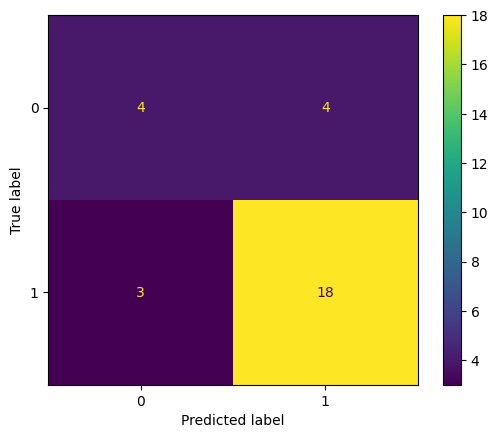

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay as CM

# create a confusion matrix
CM.from_predictions(Y_test, predict)

In [24]:
from sklearn.metrics import precision_recall_fscore_support

# Calculate precision, recall, and F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')

print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')

print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}")

Micro-averaged Precision: 0.76
Micro-averaged Recall: 0.76
Micro-averaged F1-score: 0.76


Macro-averaged Precision: 0.69
Macro-averaged Recall: 0.68
Macro-averaged F1-score: 0.69


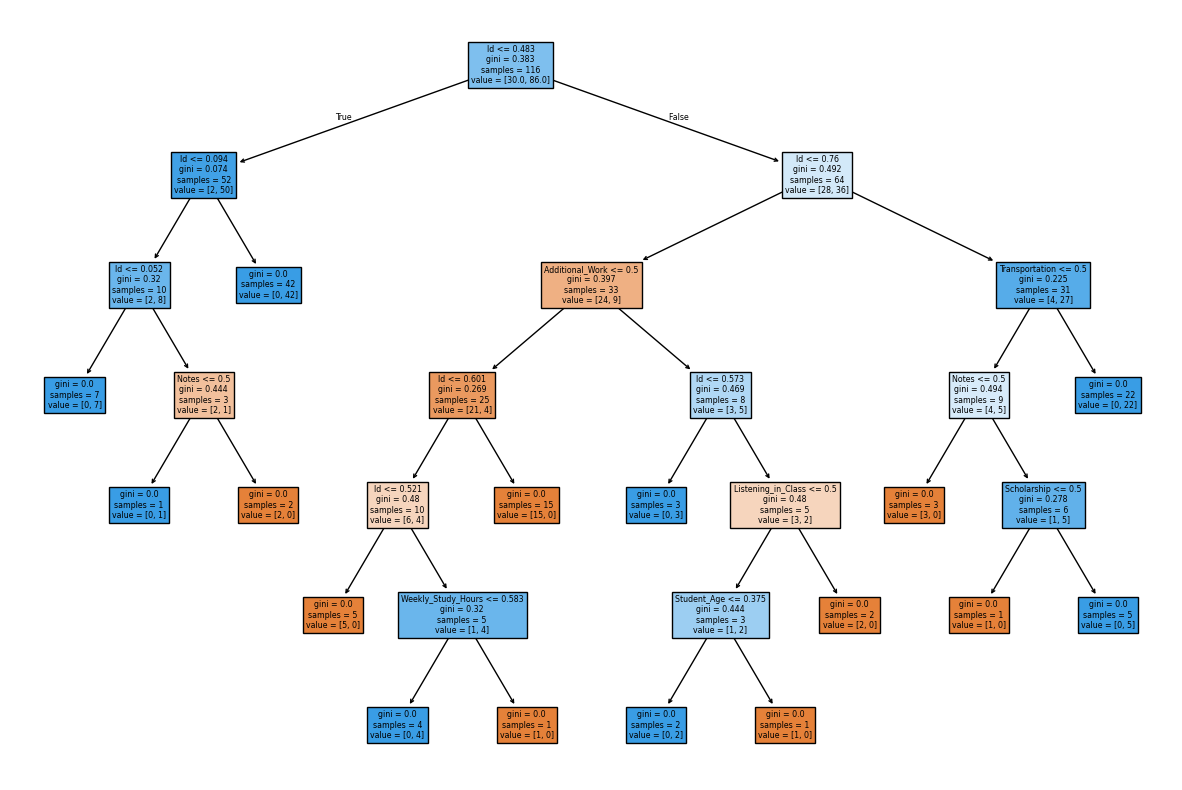

In [25]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.show()

In [32]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# this is the list of parameters we will tune. Some are fixed values some are distributions
tuned_parameters = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(3, 9),  # Draw from a uniform distribution between 3 and 15
    'min_samples_split': randint(3, 9),  # Draw from a uniform distribution between 2 and 10
    'max_features': ['sqrt', 'log2', None]
}

# we will tune against f1_macro (to find the best choice)
score = 'f1_macro' # arbitrary choice

print(f"Tuning hyperparameters for {score}")
print("\n")

# do the search using 5 folds/chunks
clf = RandomizedSearchCV(DTC(), tuned_parameters, cv=5, random_state=1984,
                         scoring= score, n_iter=20, refit=True)

# pass the data to fit/train
clf.fit(X_train, Y_train)

print("Best parameters set found on the training set:")
print(clf.best_params_)


Tuning hyperparameters for f1_macro


Best parameters set found on the training set:
{'criterion': 'gini', 'max_depth': 7, 'max_features': None, 'min_samples_split': 7}


In [34]:
DTC_algo = DTC(**clf.best_params_) # get the best parameters from grid search
DTC_model = DTC_algo.fit(X_train, Y_train)

In [35]:
# predict the test data
predict = DTC_model.predict(X_test)

# seperate the first five predictions and the first five real values in Y_test
for i in range(5):
  print(f'Predicted: {round(predict[i],2)}')
  print(f'Real: {Y_test[i]}')
  print("\n")

print("\n")

print(f'Accuracy: {round(accuracy_score(Y_test, predict),2)}')

Predicted: 1
Real: 0


Predicted: 1
Real: 1


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 1
Real: 1




Accuracy: 0.76


Micro-averaged Precision: 0.76
Micro-averaged Recall: 0.76
Micro-averaged F1-score: 0.76


Macro-averaged Precision: 0.72
Macro-averaged Recall: 0.76
Macro-averaged F1-score: 0.73




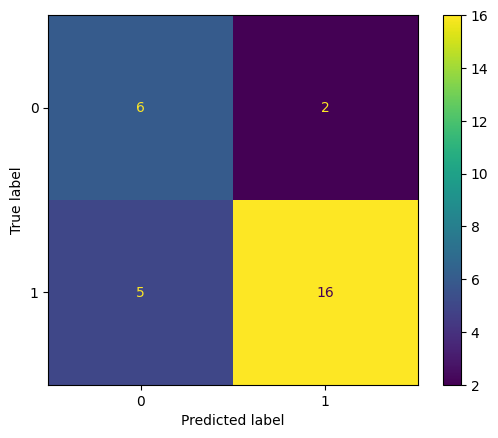

In [36]:
# create a confusion matrix
CM.from_predictions(Y_test, predict)

# Calculate precision, recall, and F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')

print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')

print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

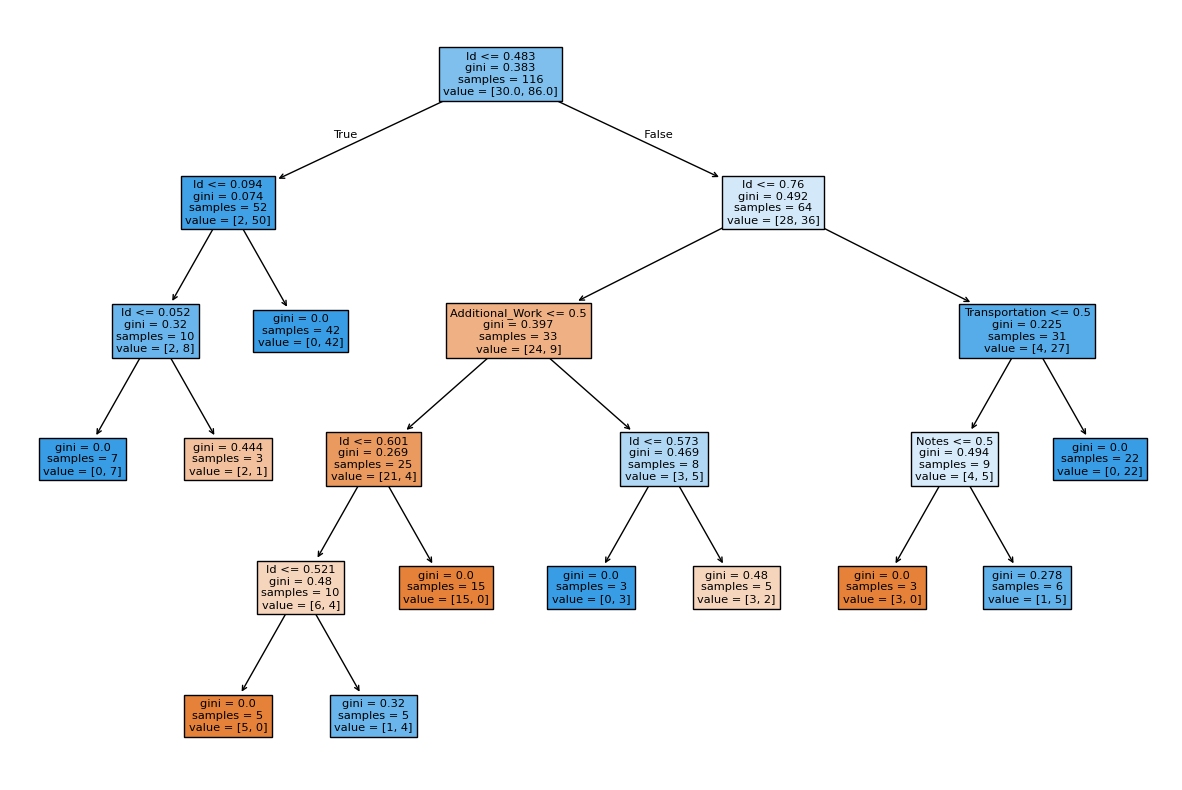

In [37]:
plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.show()

And now its time for modelling ...



Your turn :)

### 1. 修复并填充特征集中的空值 (Imputation)
由于 `Attendance` 列等可能含有 NaN 值，我们先使用简单插补器（SimpleImputer）用众数或中位数填充空值，确保模型能正常输入。

In [ ]:
from sklearn.impute import SimpleImputer
import pandas as pd

# 1. 检查并移除全是 NaN 的 'Attendance' 列
# 由于 'Attendance' 在之前的映射中全部变为了 NaN，我们将其从特征中剔除
X_train_cleaned = X_train.drop(columns=['Attendance'], errors='ignore')
X_test_cleaned = X_test.drop(columns=['Attendance'], errors='ignore')

# 2. 创建插补器，对其他可能有缺失值的特征进行中位数填充
imputer = SimpleImputer(strategy='median')

# 3. 填充训练集和测试集
X_train_filled = pd.DataFrame(imputer.fit_transform(X_train_cleaned), columns=X_train_cleaned.columns)
X_test_filled = pd.DataFrame(imputer.transform(X_test_cleaned), columns=X_test_cleaned.columns)

# 4. 检查是否还存在空值
print("训练集空值数量:", X_train_filled.isnull().sum().sum())
print("测试集空值数量:", X_test_filled.isnull().sum().sum())

训练集空值数量: 0
测试集空值数量: 0


### 2. 训练分类模型
我们将构建并训练两个常用的分类模型：
1. **逻辑回归 (Logistic Regression)**：简单、直观，适合基准测试。
2. **随机森林 (Random Forest)**：强大的集成树模型，能自动处理非线性特征关系。

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. 初始化模型
lr_model = LogisticRegression(random_state=1984, max_iter=1000)
rf_model = RandomForestClassifier(random_state=1984, n_estimators=100)

# 2. 训练模型
lr_model.fit(X_train_filled, Y_train)
rf_model.fit(X_train_filled, Y_train)

# 3. 在测试集上进行预测
lr_preds = lr_model.predict(X_test_filled)
rf_preds = rf_model.predict(X_test_filled)

# 4. 评估模型准确率
print(f"逻辑回归测试集准确率: {accuracy_score(Y_test, lr_preds):.4f}")
print(f"随机森林测试集准确率: {accuracy_score(Y_test, rf_preds):.4f}")

逻辑回归测试集准确率: 0.6897
随机森林测试集准确率: 0.6897


### 3. 查看详细的评估报告
我们可以查看分类报告（包含精确率 Precision、召回率 Recall 和 F1-score）以及混淆矩阵，来更全面地了解模型的效果。

In [ ]:
print("=== 随机森林分类报告 ===")
print(classification_report(Y_test, rf_preds, target_names=['Fail', 'Pass']))

print("=== 随机森林混淆矩阵 ===")
print(confusion_matrix(Y_test, rf_preds))

=== 随机森林分类报告 ===
              precision    recall  f1-score   support

        Fail       0.40      0.25      0.31         8
        Pass       0.75      0.86      0.80        21

    accuracy                           0.69        29
   macro avg       0.57      0.55      0.55        29
weighted avg       0.65      0.69      0.66        29

=== 随机森林混淆矩阵 ===
[[ 2  6]
 [ 3 18]]
